# Evaluating Retrieval Quality

The dashboard returns books that are *similar* to the query, but are they *good* recommendations? This notebook
measures that, and compares the current search (OpenAI embeddings) against cheaper alternatives.

**Method**
1. **40 test queries** written the way a user would type them, covering fiction, nonfiction, children's books
   and mood-based requests.
2. **6 retrieval systems** each return their top 10 books per query.
3. **Pooling:** every book that appears in *any* system's top 10 is judged, so every system is scored on fully
   judged results.
4. **LLM as judge:** `gpt-5.4-mini` grades each (query, book) pair as **2 = highly relevant**,
   **1 = partially relevant** or **0 = not relevant**. It never sees which system retrieved the book.
5. **Human check:** a stratified sample of 50 judgments is labelled by hand, blind to the LLM's grade, to
   measure how far the judge can be trusted.
6. **Metrics:** nDCG@10 (primary), Precision@10 and MRR, with paired bootstrap confidence intervals.

In [1]:
import json
import os
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import chromadb
from dotenv import load_dotenv
from openai import OpenAI
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

warnings.filterwarnings("ignore")
load_dotenv("../.env", override=True)

DATA_DIR = Path("../data")
EVAL_DIR = DATA_DIR / "evaluation"
CACHE_DIR = EVAL_DIR / "cache"          # git-ignored: document embeddings
CACHE_DIR.mkdir(parents=True, exist_ok=True)

JUDGE_MODEL = "gpt-5.4-mini-2026-03-17"  # pinned snapshot, so the judgments are reproducible
TOP_K = 10
SEED = 42
client = OpenAI()

books = pd.read_csv(DATA_DIR / "processed" / "books_with_emotions.csv")
print(f"{len(books)} books")

5197 books


## 1. Test queries

In [2]:
queries = pd.DataFrame([
    # Fiction
    ("fiction", "A story about forgiveness"),
    ("fiction", "A detective solving a murder in Victorian London"),
    ("fiction", "A love story set during World War II"),
    ("fiction", "A dystopian future where the government controls everything"),
    ("fiction", "A coming-of-age story about growing up in a small town"),
    ("fiction", "A fantasy adventure with dragons and magic"),
    ("fiction", "A ghost story set in an old haunted house"),
    ("fiction", "A family saga spanning several generations"),
    ("fiction", "A funny novel that will make me laugh out loud"),
    ("fiction", "A psychological thriller with an unreliable narrator"),
    ("fiction", "A novel about the immigrant experience in America"),
    ("fiction", "Science fiction about first contact with aliens"),
    ("fiction", "A story about friendship between two women"),
    ("fiction", "A historical novel set in ancient Rome"),
    ("fiction", "A legal thriller set in a courtroom"),
    ("fiction", "A story of survival in the wilderness"),
    # Nonfiction
    ("nonfiction", "A biography of a famous scientist"),
    ("nonfiction", "A history of World War II"),
    ("nonfiction", "An introduction to Buddhist philosophy"),
    ("nonfiction", "A book that explains how the human brain works"),
    ("nonfiction", "A memoir of someone overcoming addiction"),
    ("nonfiction", "A guide to Christian prayer and spiritual growth"),
    ("nonfiction", "A history of the American Civil War"),
    ("nonfiction", "A book about evolution and natural selection"),
    ("nonfiction", "Literary criticism of Shakespeare's plays"),
    ("nonfiction", "A collection of essays on politics and society"),
    ("nonfiction", "A book about the history of mathematics"),
    ("nonfiction", "A memoir about growing up in poverty"),
    ("nonfiction", "A book on ancient Greek philosophy"),
    ("nonfiction", "A travel book about exploring Africa"),
    # Children's
    ("children", "A book to teach children about nature"),
    ("children", "A picture book about a brave little animal"),
    ("children", "A story for kids about going to school for the first time"),
    ("children", "An adventure book for young readers with talking animals"),
    ("children", "A book for children about dinosaurs"),
    ("children", "A bedtime story about friendship"),
    # Mood / vague
    ("mood", "Something uplifting to read after a hard week"),
    ("mood", "A dark and disturbing book that will stay with me"),
    ("mood", "A sad book that will make me cry"),
    ("mood", "Poetry about love and loss"),
], columns=["type", "query"])
queries.index.name = "query_id"
queries.to_csv(EVAL_DIR / "queries.csv")
queries["type"].value_counts()

type
fiction       16
nonfiction    14
children       6
mood           4
Name: count, dtype: int64

## 2. Retrieval systems

| System | How it works | Cost per search |
|---|---|---|
| **OpenAI** `text-embedding-3-small` | The dashboard's current search. Document vectors are read from Chroma. | 1 API call |
| `bge-small-en-v1.5` | Open-source embeddings, run locally. Uses bge's recommended query instruction. | Free |
| `all-MiniLM-L6-v2` | Open-source embeddings, run locally. | Free |
| **BM25** | Classic keyword search. | Free |
| **Hybrid: BM25 + OpenAI** | Reciprocal rank fusion of the two ranked lists. | 1 API call |
| **Hybrid: BM25 + bge** | Reciprocal rank fusion of the two ranked lists. | Free |

One extra row measures a bug found in the dashboard: it retrieved the right 50 books but displayed them in CSV
file order instead of relevance order. **OpenAI, dashboard order (bug)** reproduces what users actually saw.

In [3]:
descriptions = books["description"].tolist()
isbns = books["isbn13"].values

# OpenAI: document vectors already stored in Chroma (unit length, so dot product = cosine similarity)
collection = chromadb.PersistentClient(path=str(DATA_DIR / "chroma_db")).get_collection("langchain")
stored = collection.get(include=["embeddings", "documents"])
openai_docs = pd.DataFrame(
    np.array(stored["embeddings"]),
    index=[int(d.strip().strip('"').split()[0]) for d in stored["documents"]],
).loc[isbns].values


def encode_openai(texts):
    response = client.embeddings.create(model="text-embedding-3-small", input=texts)
    return np.array([item.embedding for item in response.data])


local_models = {
    "bge-small-en-v1.5": ("BAAI/bge-small-en-v1.5", "Represent this sentence for searching relevant passages: "),
    "all-MiniLM-L6-v2": ("sentence-transformers/all-MiniLM-L6-v2", ""),
}
encoders, local_docs = {}, {}
for name, (model_id, _) in local_models.items():
    encoders[name] = SentenceTransformer(model_id, device="cpu")
    cache = CACHE_DIR / f"{name}.npy"
    if cache.exists():
        local_docs[name] = np.load(cache)
    else:
        start = time.time()
        local_docs[name] = encoders[name].encode(descriptions, batch_size=64, normalize_embeddings=True)
        np.save(cache, local_docs[name])
        print(f"Encoded {len(descriptions)} books with {name} in {time.time() - start:.0f}s")


def tokenize(text):
    return [w for w in "".join(c.lower() if c.isalnum() else " " for c in text).split()
            if w not in ENGLISH_STOP_WORDS]


bm25 = BM25Okapi([tokenize(d) for d in descriptions])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [4]:
def dense_ranking(doc_vectors, query_vector):
    return np.argsort(-(doc_vectors @ query_vector))


def rrf(*rankings, k=60, depth=100):
    """Reciprocal rank fusion: score = sum of 1 / (k + rank) across the ranked lists."""
    scores = {}
    for ranking in rankings:
        for rank, doc in enumerate(ranking[:depth]):
            scores[doc] = scores.get(doc, 0) + 1 / (k + rank + 1)
    return np.array(sorted(scores, key=scores.get, reverse=True))


query_texts = queries["query"].tolist()
latency = {}
openai_queries = []
for query in query_texts:  # one call per query, as in the dashboard, so latency is realistic
    start = time.time()
    openai_queries.append(encode_openai([query])[0])
    latency.setdefault("OpenAI", []).append(time.time() - start)

rankings = {name: [] for name in ["OpenAI", "bge-small", "MiniLM", "BM25", "Hybrid: BM25 + OpenAI", "Hybrid: BM25 + bge"]}
for i, query in enumerate(query_texts):
    rankings["OpenAI"].append(dense_ranking(openai_docs, openai_queries[i]))

    start = time.time()
    q = encoders["bge-small-en-v1.5"].encode(local_models["bge-small-en-v1.5"][1] + query, normalize_embeddings=True)
    rankings["bge-small"].append(dense_ranking(local_docs["bge-small-en-v1.5"], q))
    latency.setdefault("bge-small", []).append(time.time() - start)

    start = time.time()
    q = encoders["all-MiniLM-L6-v2"].encode(query, normalize_embeddings=True)
    rankings["MiniLM"].append(dense_ranking(local_docs["all-MiniLM-L6-v2"], q))
    latency.setdefault("MiniLM", []).append(time.time() - start)

    start = time.time()
    rankings["BM25"].append(np.argsort(-bm25.get_scores(tokenize(query))))
    latency.setdefault("BM25", []).append(time.time() - start)

    rankings["Hybrid: BM25 + OpenAI"].append(rrf(rankings["BM25"][i], rankings["OpenAI"][i]))
    rankings["Hybrid: BM25 + bge"].append(rrf(rankings["BM25"][i], rankings["bge-small"][i]))

# What the dashboard actually showed before the fix: the top 50 OpenAI results, but re-ordered by
# their row position in the CSV, because `books[books["isbn13"].isin(...)]` keeps file order.
rankings["OpenAI, dashboard order (bug)"] = [np.sort(r[:50]) for r in rankings["OpenAI"]]

latency = {k: np.mean(v) for k, v in latency.items()}
print("Mean query latency (ms):", {k: round(v * 1000, 1) for k, v in latency.items()})

top_k = {name: [isbns[r[:TOP_K]] for r in ranks] for name, ranks in rankings.items()}

Mean query latency (ms): {'OpenAI': np.float64(222.8), 'bge-small': np.float64(18.0), 'MiniLM': np.float64(9.2), 'BM25': np.float64(5.1)}


### Re-ranking with cross-encoders

A cross-encoder reads the query and a book's description *together*, which is more accurate than comparing two
separate embeddings but too slow to run on every book. The standard pattern: retrieve the top 50 with OpenAI,
then let the cross-encoder re-order them. Latency is the cross-encoder's time per query, on top of the OpenAI search.

In [5]:
from sentence_transformers import CrossEncoder

RERANK_DEPTH = 50
rerankers = {
    "OpenAI + ms-marco-MiniLM reranker": "cross-encoder/ms-marco-MiniLM-L-6-v2",
    "OpenAI + bge-reranker-base": "BAAI/bge-reranker-base",
}
book_texts = (books["title_and_subtitle"] + ". " + books["description"]).tolist()

for name, model_id in rerankers.items():
    reranker = CrossEncoder(model_id, device="cpu", max_length=512)
    rankings[name], times = [], []
    for i, query in enumerate(query_texts):
        candidates = rankings["OpenAI"][i][:RERANK_DEPTH]
        start = time.time()
        scores = reranker.predict([(query, book_texts[c]) for c in candidates], batch_size=16)
        times.append(time.time() - start)
        rankings[name].append(candidates[np.argsort(-scores)])
    latency[name] = np.mean(times)
    print(f"{name}: {np.mean(times) * 1000:.0f} ms per query to re-rank {RERANK_DEPTH} books")

top_k = {name: [isbns[r[:TOP_K]] for r in ranks] for name, ranks in rankings.items()}

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

OpenAI + ms-marco-MiniLM reranker: 1562 ms per query to re-rank 50 books


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

OpenAI + bge-reranker-base: 11541 ms per query to re-rank 50 books


## 3. Pooling and LLM judging

Every (query, book) pair that appears in any system's top 10 is judged once. Judgments are cached, so re-running
the notebook only judges new pairs.

In [6]:
pool = sorted({(qid, int(isbn)) for name in top_k for qid, books_ in enumerate(top_k[name]) for isbn in books_})
print(f"{len(pool)} unique (query, book) pairs to judge, "
      f"{len(pool) / len(queries):.1f} per query out of a maximum of {len(top_k) * TOP_K}")

JUDGE_PROMPT = """You are evaluating a book recommendation system.

A user searched for: "{query}"

Recommended book:
Title: {title}
Author(s): {authors}
Category: {category}
Description: {description}

How well does this book match what the user asked for?
2 = highly relevant: clearly matches the request; a good recommendation for this user.
1 = partially relevant: related to the request but misses an important part of it
    (for example the right topic but the wrong genre, audience or focus).
0 = not relevant.

Judge only from the information above. Give a one-sentence reason, then the grade."""

GRADE_SCHEMA = {"type": "json_schema", "json_schema": {"name": "relevance", "strict": True, "schema": {
    "type": "object",
    "properties": {"reason": {"type": "string"}, "grade": {"type": "integer", "enum": [0, 1, 2]}},
    "required": ["reason", "grade"], "additionalProperties": False}}}

book_by_isbn = books.set_index("isbn13")


def judge(pair):
    qid, isbn = pair
    book = book_by_isbn.loc[isbn]
    prompt = JUDGE_PROMPT.format(query=queries.loc[qid, "query"], title=book["title_and_subtitle"],
                                 authors=str(book["authors"]).replace(";", ", "),
                                 category=book["simple_categories"], description=book["description"][:2000])
    for attempt in range(5):
        try:
            r = client.chat.completions.create(model=JUDGE_MODEL, reasoning_effort="low",
                                               messages=[{"role": "user", "content": prompt}],
                                               response_format=GRADE_SCHEMA)
            result = json.loads(r.choices[0].message.content)
            return {"query_id": qid, "isbn13": isbn, "grade": result["grade"], "reason": result["reason"],
                    "input_tokens": r.usage.prompt_tokens, "output_tokens": r.usage.completion_tokens}
        except Exception as error:
            last_error = error
            time.sleep(2 ** attempt)
    raise RuntimeError(f"Judging failed for {pair}: {last_error}")


JUDGMENTS = EVAL_DIR / "llm_judgments.csv"
judgments = pd.read_csv(JUDGMENTS) if JUDGMENTS.exists() else pd.DataFrame(columns=["query_id", "isbn13"])
done = set(zip(judgments["query_id"], judgments["isbn13"]))
todo = [p for p in pool if p not in done]

if todo:
    start = time.time()
    with ThreadPoolExecutor(max_workers=8) as executor:
        new = pd.DataFrame(list(executor.map(judge, todo)))
    judgments = pd.concat([judgments, new], ignore_index=True)
    judgments.to_csv(JUDGMENTS, index=False)
    print(f"Judged {len(todo)} pairs in {time.time() - start:.0f}s")

print(f"Tokens used: {judgments['input_tokens'].sum():,} input, {judgments['output_tokens'].sum():,} output")
judgments["grade"].value_counts().sort_index().rename("pairs")

1662 unique (query, book) pairs to judge, 41.5 per query out of a maximum of 90
Tokens used: 477,317.0 input, 137,324.0 output


grade
0.0    415
1.0    918
2.0    329
Name: pairs, dtype: int64

## 4. Results

In [7]:
grades = {(r.query_id, r.isbn13): r.grade for r in judgments.itertuples()}
# Ideal ranking for nDCG uses every judged book for the query
ideal = {qid: sorted([g for (q, _), g in grades.items() if q == qid], reverse=True) for qid in queries.index}
discounts = 1 / np.log2(np.arange(2, TOP_K + 2))


def per_query_metrics(name):
    rows = []
    for qid, retrieved in enumerate(top_k[name]):
        g = np.array([grades[(qid, int(i))] for i in retrieved])
        ideal_dcg = np.sum(np.array(ideal[qid][:TOP_K]) * discounts[:len(ideal[qid][:TOP_K])])
        highly = np.flatnonzero(g == 2)
        rows.append({
            "nDCG@10": np.sum(g * discounts) / ideal_dcg if ideal_dcg else 0.0,
            "P@10": np.mean(g == 2),
            "P@10 (incl. partial)": np.mean(g >= 1),
            "MRR": 1 / (highly[0] + 1) if len(highly) else 0.0,
        })
    return pd.DataFrame(rows, index=queries.index)


metrics = {name: per_query_metrics(name) for name in top_k}
summary = pd.DataFrame({name: m.mean() for name, m in metrics.items()}).T
summary["latency (ms)"] = [latency[n] * 1000 if n in latency else np.nan for n in summary.index]
summary["needs API"] = ["OpenAI" in n for n in summary.index]
summary = summary.sort_values("nDCG@10", ascending=False)
summary.round(3)

,nDCG@10,P@10,P@10 (incl. partial),MRR,latency (ms),needs API
OpenAI,0.821,0.380,0.940,0.767,222.791,True
OpenAI + bge-reranker-base,0.752,0.355,0.898,0.589,11541.118,True
OpenAI + ms-marco-MiniLM reranker,0.748,0.352,0.905,0.600,1561.775,True
Hybrid: BM25 + OpenAI,0.737,0.292,0.890,0.654,NaN,True
Hybrid: BM25 + bge,0.667,0.275,0.818,0.601,NaN,False
bge-small,0.661,0.265,0.798,0.606,17.955,False
MiniLM,0.650,0.230,0.790,0.620,9.201,False
BM25,0.568,0.182,0.712,0.458,5.072,False
"OpenAI, dashboard order (bug)",0.555,0.210,0.735,0.379,NaN,True


In [8]:
rng = np.random.default_rng(SEED)
samples = rng.integers(0, len(queries), size=(10_000, len(queries)))
baseline = metrics["OpenAI"]["nDCG@10"].values

rows = []
for name in summary.index:
    diff = metrics[name]["nDCG@10"].values - baseline
    boot = diff[samples].mean(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])
    rows.append({"system": name, "nDCG@10": metrics[name]["nDCG@10"].mean(),
                 "vs OpenAI": diff.mean(), "95% CI low": low, "95% CI high": high,
                 "significant": (low > 0) or (high < 0)})
comparison = pd.DataFrame(rows).set_index("system")
comparison.round(3)

,nDCG@10,vs OpenAI,95% CI low,95% CI high,significant
system,,,,,
OpenAI,0.821,0.000,0.000,0.000,False
OpenAI + bge-reranker-base,0.752,-0.070,-0.102,-0.037,True
OpenAI + ms-marco-MiniLM reranker,0.748,-0.073,-0.120,-0.030,True
Hybrid: BM25 + OpenAI,0.737,-0.085,-0.118,-0.053,True
Hybrid: BM25 + bge,0.667,-0.154,-0.202,-0.108,True
bge-small,0.661,-0.160,-0.216,-0.110,True
MiniLM,0.650,-0.172,-0.223,-0.121,True
BM25,0.568,-0.253,-0.303,-0.207,True
"OpenAI, dashboard order (bug)",0.555,-0.267,-0.336,-0.201,True


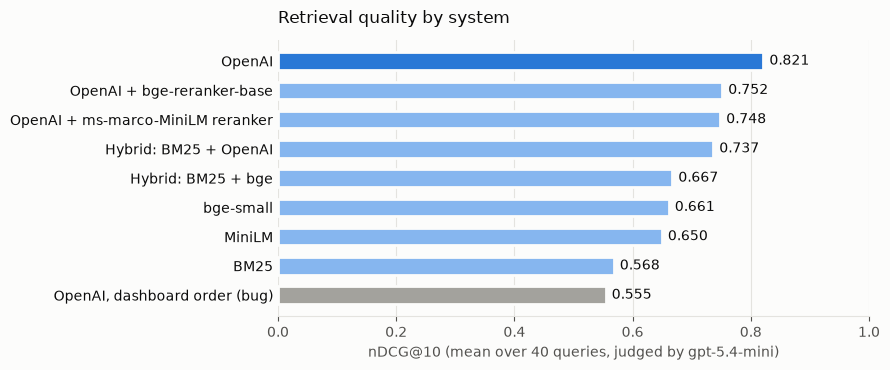

In [9]:
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
HIGHLIGHT, OTHER, BUG = "#2a78d6", "#86b6ef", "#a3a29d"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED, "ytick.color": INK,
    "text.color": INK, "font.size": 10,
})

plot_data = comparison.sort_values("nDCG@10")
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [HIGHLIGHT if name == plot_data["nDCG@10"].idxmax() else BUG if "bug" in name else OTHER
          for name in plot_data.index]
bars = ax.barh(plot_data.index, plot_data["nDCG@10"], color=colors, height=0.6, edgecolor=SURFACE, linewidth=2)
for bar, value in zip(bars, plot_data["nDCG@10"]):
    ax.text(value + 0.01, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("nDCG@10 (mean over 40 queries, judged by gpt-5.4-mini)")
ax.set_title("Retrieval quality by system", loc="left", fontsize=12, color=INK, pad=12)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("../screenshots/retrieval-ndcg.png", dpi=150, facecolor=SURFACE)
plt.show()

In [10]:
by_type = pd.DataFrame({name: m["nDCG@10"].groupby(queries["type"]).mean() for name, m in metrics.items()})
by_type[summary.index].round(3)

,OpenAI,OpenAI + bge-reranker-base,OpenAI + ms-marco-MiniLM reranker,Hybrid: BM25 + OpenAI,Hybrid: BM25 + bge,bge-small,MiniLM,BM25,"OpenAI, dashboard order (bug)"
type,,,,,,,,,
children,0.816,0.754,0.575,0.653,0.494,0.517,0.439,0.428,0.575
fiction,0.822,0.744,0.760,0.755,0.722,0.672,0.619,0.613,0.587
mood,0.818,0.743,0.827,0.708,0.727,0.856,0.647,0.455,0.693
nonfiction,0.824,0.762,0.787,0.760,0.663,0.656,0.776,0.610,0.470


### Hardest queries for the current system

In [11]:
hardest = queries.assign(**{name: metrics[name]["nDCG@10"] for name in ["OpenAI", "bge-small", "BM25"]})
hardest.sort_values("OpenAI").head(8).round(3)

,type,query,OpenAI,bge-small,BM25
query_id,,,,,
18,nonfiction,An introduction to Buddhist philosophy,0.618,0.669,0.486
33,children,An adventure book for young readers with talki...,0.629,0.414,0.446
25,nonfiction,A collection of essays on politics and society,0.643,0.610,0.581
9,fiction,A psychological thriller with an unreliable na...,0.717,0.644,0.427
0,fiction,A story about forgiveness,0.722,0.340,0.576
12,fiction,A story about friendship between two women,0.728,0.516,0.520
27,nonfiction,A memoir about growing up in poverty,0.743,0.532,0.623
3,fiction,A dystopian future where the government contro...,0.752,0.643,0.586


## 5. How far can the LLM judge be trusted?

50 judgments were sampled (stratified by the LLM's grade) into a spreadsheet **without** the LLM's grade and
graded by hand on the same 0/1/2 scale. The graded sheet is `data/evaluation/human_check.csv`.

In [12]:
HUMAN = EVAL_DIR / "human_check.xlsx"
HUMAN_CSV = EVAL_DIR / "human_check.csv"  # the graded sheet, saved from Excel as CSV
if not HUMAN.exists() and not HUMAN_CSV.exists():
    from openpyxl.styles import Alignment, Font, PatternFill
    from openpyxl.worksheet.datavalidation import DataValidation

    sample = (judgments.groupby("grade", group_keys=False)
              .apply(lambda g: g.sample(min(len(g), 17), random_state=SEED))
              .sample(frac=1, random_state=SEED).head(50))
    sheet = pd.DataFrame({
        # Text key, so Excel can't turn the 13-digit ISBN into 9.78E+12
        "pair_id": [f"{q}-{i}" for q, i in zip(sample["query_id"], sample["isbn13"])],
        "query": sample["query_id"].map(queries["query"]).values,
        "title": sample["isbn13"].map(book_by_isbn["title_and_subtitle"]).values,
        "authors": sample["isbn13"].map(book_by_isbn["authors"]).str.replace(";", ", ").values,
        "description": sample["isbn13"].map(book_by_isbn["description"]).values,
        "human_grade": None,
    })
    with pd.ExcelWriter(HUMAN, engine="openpyxl") as writer:
        sheet.to_excel(writer, sheet_name="grades", index=False)
        ws = writer.sheets["grades"]
        for col, width in zip("ABCDEF", [12, 30, 30, 20, 90, 13]):
            ws.column_dimensions[col].width = width
        for row in ws.iter_rows(min_row=2):
            for cell in row:
                cell.alignment = Alignment(wrap_text=True, vertical="top")
        for cell in ws[1]:
            cell.font = Font(bold=True)
        ws.freeze_panes = "B2"
        grade_rule = DataValidation(type="list", formula1='"0,1,2"', allow_blank=True)
        ws.add_data_validation(grade_rule)
        grade_rule.add(f"F2:F{len(sheet) + 1}")
        for cell in ws["F"][1:]:
            cell.fill = PatternFill("solid", fgColor="FFF4CC")

        guide = writer.book.create_sheet("how to grade")
        for line in ["Grade how well each book matches the query, using only the information shown:",
                     "2 = highly relevant: clearly matches the request; a good recommendation.",
                     "1 = partially relevant: related, but misses an important part (e.g. right topic, wrong genre or audience).",
                     "0 = not relevant.",
                     "Fill in the yellow human_grade column on the 'grades' sheet, save, and re-run the notebook cell."]:
            guide.append([line])
        guide.column_dimensions["A"].width = 110
    print(f"Wrote {len(sheet)} rows to {HUMAN}. Fill in human_grade and re-run this cell.")

if HUMAN_CSV.exists():
    human = pd.read_csv(HUMAN_CSV, dtype={"pair_id": str}, encoding="utf-8-sig")
else:
    human = pd.read_excel(HUMAN, sheet_name="grades", dtype={"pair_id": str})
human[["query_id", "isbn13"]] = human["pair_id"].str.split("-", expand=True).astype(int)
if human["human_grade"].notna().all():
    from sklearn.metrics import cohen_kappa_score
    merged = human.merge(judgments[["query_id", "isbn13", "grade"]], on=["query_id", "isbn13"])
    merged["human_grade"] = merged["human_grade"].astype(int)
    exact = (merged["human_grade"] == merged["grade"]).mean()
    binary = ((merged["human_grade"] == 2) == (merged["grade"] == 2)).mean()
    kappa = cohen_kappa_score(merged["human_grade"], merged["grade"].astype(int), weights="quadratic")
    within_one = ((merged["human_grade"] - merged["grade"]).abs() <= 1).mean()
    print(f"Exact agreement: {exact:.0%}   Within one grade: {within_one:.0%}   "
          f"Agreement on 'highly relevant': {binary:.0%}   Quadratic-weighted Cohen's kappa: {kappa:.2f}")
    print(f"Mean grade: human {merged['human_grade'].mean():.2f}, LLM {merged['grade'].mean():.2f}")
    display(pd.crosstab(merged["human_grade"].rename("human"), merged["grade"].astype(int).rename("LLM")))
else:
    print(f"{human['human_grade'].isna().sum()} of {len(human)} rows still need a human grade.")

Exact agreement: 66%   Within one grade: 96%   Agreement on 'highly relevant': 78%   Quadratic-weighted Cohen's kappa: 0.69
Mean grade: human 1.20, LLM 0.98


LLM,0,1,2
human,,,
0,12,2,1
1,4,6,0
2,1,9,15


## 6. Summary

| System | nDCG@10 | P@10 | MRR | Latency per search |
|---|---|---|---|---|
| **OpenAI `text-embedding-3-small` (current)** | **0.821** | **0.380** | **0.767** | ~200-400 ms (API call) |
| OpenAI + bge-reranker-base | 0.752 | 0.355 | 0.589 | + ~12 s on CPU |
| OpenAI + ms-marco-MiniLM reranker | 0.748 | 0.352 | 0.600 | + ~1.5 s on CPU |
| Hybrid: BM25 + OpenAI | 0.737 | 0.292 | 0.654 | ~200-400 ms |
| Hybrid: BM25 + bge | 0.667 | 0.275 | 0.601 | ~30 ms |
| bge-small-en-v1.5 | 0.661 | 0.265 | 0.606 | ~22 ms |
| all-MiniLM-L6-v2 | 0.650 | 0.230 | 0.620 | ~11 ms |
| BM25 | 0.568 | 0.182 | 0.458 | ~6 ms |
| *OpenAI, dashboard order (bug)* | *0.555* | *0.210* | *0.379* | |

**Findings**
- **The current OpenAI search is the best system.** Every alternative is significantly worse (each 95% bootstrap
  CI for the difference is entirely below zero).
- **A ranking bug in the dashboard was costing a third of the quality.** It showed the right 50 books in CSV file
  order instead of relevance order (nDCG 0.555). Fixing it restores 0.821, a 48% relative improvement.
- **Re-ranking made results worse**, and was 5-40x slower on CPU. Both cross-encoders are trained on web
  question-answering data (MS MARCO-style), where relevance means "this passage answers the question". Book
  requests like "a story about forgiveness" are about theme and tone, which the bi-encoder captures better.
- **Adding keyword search (BM25) also hurt.** Descriptive queries share common words ("story", "life", "book") with
  many unrelated descriptions, so BM25 adds noise to the dense ranking.
- **Open-source embeddings trail OpenAI by about 0.16 nDCG.** They are 15-30x faster but not good enough to switch.
  Since a search embeds only about 10 tokens, OpenAI's cost per search is negligible.

**Judge reliability**
- 50 judgments were graded by hand, blind to the LLM's grade: **quadratic-weighted Cohen's kappa 0.69**
  (substantial agreement), **96% within one grade**, 78% agreement on "highly relevant".
- The LLM judge is **stricter** than the human (mean grade 0.98 vs 1.20), so absolute precision figures are
  conservative. Because it is equally strict for every system, the comparison between systems is unaffected.

**Limitations**
- 40 queries is enough to separate these systems (the confidence intervals do not overlap zero) but not to draw
  conclusions about small subgroups, such as the 4 mood queries.
- Judgments are pooled from the top 10 of each system, so books that no system retrieved are never judged.
